Required Libraries Install

In [ ]:

!pip -q install pandas numpy scikit-learn nltk xgboost matplotlib seaborn


Import  libraries

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

from google.colab import files
from nltk.sentiment.vader import SentimentIntensityAnalyzer

nltk.download("vader_lexicon")

print("All libraries imported successfully!")


All libraries imported successfully!


[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


Amazon CSV File Upload

In [ ]:

from google.colab import files

uploaded = files.upload()


Saving amazon_reviews.txt to amazon_reviews.txt


Verify Dataset Upload

In [ ]:

import pandas as pd

filename = next(iter(uploaded))

print("Uploaded File:", filename)

df = pd.read_csv(filename, sep=None, engine="python")

print("\nDataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

# Check whether review date column is available
print("\nReview Date Column Check:")

date_columns = [
    col for col in df.columns
    if "date" in col.lower()
    or "time" in col.lower()
    or "timestamp" in col.lower()
]

if date_columns:
    print("Date Columns Found:", date_columns)
else:
    print("No Review Date Column Found in Amazon Dataset.")
    print("Temporal Features require actual review dates.")


Uploaded File: amazon_reviews.txt

Dataset Shape: (21000, 9)

Column Names:
['DOC_ID', 'LABEL', 'RATING', 'VERIFIED_PURCHASE', 'PRODUCT_CATEGORY', 'PRODUCT_ID', 'PRODUCT_TITLE', 'REVIEW_TITLE', 'REVIEW_TEXT']

First 5 Rows:


,DOC_ID,LABEL,RATING,VERIFIED_PURCHASE,PRODUCT_CATEGORY,PRODUCT_ID,PRODUCT_TITLE,REVIEW_TITLE,REVIEW_TEXT
0,1,__label1__,4,N,PC,B00008NG7N,"Targus PAUK10U Ultra Mini USB Keypad, Black",useful,"When least you think so, this product will sav..."
1,2,__label1__,4,Y,Wireless,B00LH0Y3NM,Note 3 Battery : Stalion Strength Replacement ...,New era for batteries,Lithium batteries are something new introduced...
2,3,__label1__,3,N,Baby,B000I5UZ1Q,"Fisher-Price Papasan Cradle Swing, Starlight",doesn't swing very well.,I purchased this swing for my baby. She is 6 m...
3,4,__label1__,4,N,Office Products,B003822IRA,Casio MS-80B Standard Function Desktop Calculator,Great computing!,I was looking for an inexpensive desk calcolat...
4,5,__label1__,4,N,Beauty,B00PWSAXAM,Shine Whitening - Zero Peroxide Teeth Whitenin...,Only use twice a week,I only use it twice a week and the results are...



Review Date Column Check:
No Review Date Column Found in Amazon Dataset.
Temporal Features require actual review dates.


Upload and Verify Hotel Reviews Dataset

In [ ]:

from google.colab import files
import pandas as pd

hotel_uploaded = files.upload()


hotel_filename = next(iter(hotel_uploaded))

hotel_df = pd.read_csv(hotel_filename)

print("Hotel Dataset Shape:", hotel_df.shape)

print("\nHotel Column Names:")
print(hotel_df.columns.tolist())

print("\nFirst 5 Hotel Reviews:")
display(hotel_df.head())


Saving deceptive-opinion 2.csv to deceptive-opinion 2.csv
Hotel Dataset Shape: (1600, 5)

Hotel Column Names:
['deceptive', 'hotel', 'polarity', 'source', 'text']

First 5 Hotel Reviews:


,deceptive,hotel,polarity,source,text
0,truthful,conrad,positive,TripAdvisor,We stayed for a one night getaway with family ...
1,truthful,hyatt,positive,TripAdvisor,Triple A rate with upgrade to view room was le...
2,truthful,hyatt,positive,TripAdvisor,This comes a little late as I'm finally catchi...
3,truthful,omni,positive,TripAdvisor,The Omni Chicago really delivers on all fronts...
4,truthful,hyatt,positive,TripAdvisor,I asked for a high floor away from the elevato...


Check Missing Values and Duplicates

Check Amazon Dataset

In [ ]:

print("AMAZON DATASET")

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nDataset Shape:")
print(df.shape)


AMAZON DATASET

Missing Values:
DOC_ID               0
LABEL                0
RATING               0
VERIFIED_PURCHASE    0
PRODUCT_CATEGORY     0
PRODUCT_ID           0
PRODUCT_TITLE        0
REVIEW_TITLE         0
REVIEW_TEXT          0
dtype: int64

Duplicate Rows:
0

Dataset Shape:
(21000, 9)


Check Hotel Dataset

In [ ]:

print("HOTEL DATASET")

print("\nMissing Values:")
print(hotel_df.isnull().sum())

print("\nDuplicate Rows:")
print(hotel_df.duplicated().sum())

print("\nDataset Shape:")
print(hotel_df.shape)


HOTEL DATASET

Missing Values:
deceptive    0
hotel        0
polarity     0
source       0
text         0
dtype: int64

Duplicate Rows:
4

Dataset Shape:
(1600, 5)


Data Preprocessing

In [ ]:

amazon_clean = df.copy()
hotel_clean = hotel_df.copy()

print("Amazon Dataset:", amazon_clean.shape)
print("Hotel Dataset:", hotel_clean.shape)


Amazon Dataset: (21000, 9)
Hotel Dataset: (1600, 5)


Handle Missing Review Text

In [ ]:
# Handle Missing Review Text

import pandas as pd

amazon_clean = amazon_clean.dropna(
    subset=["REVIEW_TEXT"]
).copy()

hotel_clean = hotel_clean.dropna(
    subset=["text"]
).copy()

print("Amazon After Cleaning:", amazon_clean.shape)
print("Hotel After Cleaning:", hotel_clean.shape)

print("\nAmazon Missing Review Text:",
      amazon_clean["REVIEW_TEXT"].isnull().sum())

print("Hotel Missing Review Text:",
      hotel_clean["text"].isnull().sum())

print("\nAmazon Sample:")
display(amazon_clean[["REVIEW_TEXT"]].head())

print("\nHotel Sample:")
display(hotel_clean[["text"]].head())

Amazon After Cleaning: (21000, 9)
Hotel After Cleaning: (1600, 5)

Amazon Missing Review Text: 0
Hotel Missing Review Text: 0

Amazon Sample:


,REVIEW_TEXT
0,"When least you think so, this product will sav..."
1,Lithium batteries are something new introduced...
2,I purchased this swing for my baby. She is 6 m...
3,I was looking for an inexpensive desk calcolat...
4,I only use it twice a week and the results are...



Hotel Sample:


,text
0,We stayed for a one night getaway with family ...
1,Triple A rate with upgrade to view room was le...
2,This comes a little late as I'm finally catchi...
3,The Omni Chicago really delivers on all fronts...
4,I asked for a high floor away from the elevato...


Clean Review Text

In [ ]:

import re

def clean_review(text):
    text = str(text)
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

# Clean Amazon Reviews
amazon_clean["clean_text"] = (
    amazon_clean["REVIEW_TEXT"].apply(clean_review)
)

# Clean Hotel Reviews
hotel_clean["clean_text"] = (
    hotel_clean["text"].apply(clean_review)
)

# Display Amazon Cleaned Reviews
print("Amazon Cleaned Reviews:")
display(
    amazon_clean[["REVIEW_TEXT", "clean_text"]].head()
)

# Display Hotel Cleaned Reviews
print("\nHotel Cleaned Reviews:")
display(
    hotel_clean[["text", "clean_text"]].head()
)

# Display Dataset Shapes
print("\nAmazon Dataset Shape:", amazon_clean.shape)
print("Hotel Dataset Shape:", hotel_clean.shape)


Amazon Cleaned Reviews:


,REVIEW_TEXT,clean_text
0,"When least you think so, this product will sav...","When least you think so, this product will sav..."
1,Lithium batteries are something new introduced...,Lithium batteries are something new introduced...
2,I purchased this swing for my baby. She is 6 m...,I purchased this swing for my baby. She is 6 m...
3,I was looking for an inexpensive desk calcolat...,I was looking for an inexpensive desk calcolat...
4,I only use it twice a week and the results are...,I only use it twice a week and the results are...



Hotel Cleaned Reviews:


,text,clean_text
0,We stayed for a one night getaway with family ...,We stayed for a one night getaway with family ...
1,Triple A rate with upgrade to view room was le...,Triple A rate with upgrade to view room was le...
2,This comes a little late as I'm finally catchi...,This comes a little late as I'm finally catchi...
3,The Omni Chicago really delivers on all fronts...,The Omni Chicago really delivers on all fronts...
4,I asked for a high floor away from the elevato...,I asked for a high floor away from the elevato...



Amazon Dataset Shape: (21000, 10)
Hotel Dataset Shape: (1600, 6)


Verify Cleaned Datasets

In [ ]:

print("AMAZON DATASET")
print("Total Reviews:", len(amazon_clean))
print("Missing Clean Text:",
      amazon_clean["clean_text"].isnull().sum())

print("\nHOTEL DATASET")
print("Total Reviews:", len(hotel_clean))
print("Missing Clean Text:",
      hotel_clean["clean_text"].isnull().sum())

print("\nEmpty Reviews:")
print("Amazon:",
      amazon_clean["clean_text"].eq("").sum())
print("Hotel:",
      hotel_clean["clean_text"].eq("").sum())


AMAZON DATASET
Total Reviews: 21000
Missing Clean Text: 0

HOTEL DATASET
Total Reviews: 1600
Missing Clean Text: 0

Empty Reviews:
Amazon: 0
Hotel: 0


Verify Dataset Labels and Available Features

In [ ]:

print("AMAZON DATASET LABELS")

print("\nUnique Labels:")
print(amazon_clean["LABEL"].unique())

print("\nLabel Counts:")
print(amazon_clean["LABEL"].value_counts())

print("\nTotal Reviews:")
print(len(amazon_clean))


AMAZON DATASET LABELS

Unique Labels:
['__label1__' '__label2__']

Label Counts:
LABEL
__label1__    10500
__label2__    10500
Name: count, dtype: int64

Total Reviews:
21000


Verify Amazon Metadata and Temporal Features

In [ ]:

# Verify Amazon Metadata and Temporal Features

print("AMAZON DATASET - METADATA AND TEMPORAL FEATURE CHECK")

# 1. Check available metadata columns
metadata_columns = [
    "RATING",
    "VERIFIED_PURCHASE",
    "PRODUCT_CATEGORY",
    "PRODUCT_ID",
    "REVIEW_TITLE"
]

print("\n1. Available Metadata Features:")
for col in metadata_columns:
    if col in amazon_clean.columns:
        print(col, ": Available")
    else:
        print(col, ": Not Available")

# 2. Display available metadata samples
available_metadata = [
    col for col in metadata_columns
    if col in amazon_clean.columns
]

print("\n2. Metadata Sample:")
if available_metadata:
    display(amazon_clean[available_metadata].head())
else:
    print("No listed metadata columns found.")

# 3. Check temporal features
date_columns = [
    col for col in amazon_clean.columns
    if "date" in col.lower()
    or "time" in col.lower()
    or "timestamp" in col.lower()
]

print("\n3. Temporal Features:")
if date_columns:
    print("Date/Time Columns Found:", date_columns)
else:
    print("No Date/Time Columns Available")
    print("Temporal features cannot be extracted.")

# 4. Check missing values in metadata
print("\n4. Missing Values in Metadata:")
if available_metadata:
    print(amazon_clean[available_metadata].isnull().sum())

print("\nAmazon Metadata Verification Completed!")


AMAZON DATASET - METADATA AND TEMPORAL FEATURE CHECK

1. Available Metadata Features:
RATING : Available
VERIFIED_PURCHASE : Available
PRODUCT_CATEGORY : Available
PRODUCT_ID : Available
REVIEW_TITLE : Available

2. Metadata Sample:


,RATING,VERIFIED_PURCHASE,PRODUCT_CATEGORY,PRODUCT_ID,REVIEW_TITLE
0,4,N,PC,B00008NG7N,useful
1,4,Y,Wireless,B00LH0Y3NM,New era for batteries
2,3,N,Baby,B000I5UZ1Q,doesn't swing very well.
3,4,N,Office Products,B003822IRA,Great computing!
4,4,N,Beauty,B00PWSAXAM,Only use twice a week



3. Temporal Features:
No Date/Time Columns Available
Temporal features cannot be extracted.

4. Missing Values in Metadata:
RATING               0
VERIFIED_PURCHASE    0
PRODUCT_CATEGORY     0
PRODUCT_ID           0
REVIEW_TITLE         0
dtype: int64

Amazon Metadata Verification Completed!


Verify Hotel Metadata and Temporal Features

In [ ]:

# Verify Hotel Metadata and Temporal Features

print("HOTEL DATASET COLUMNS")
print(hotel_clean.columns.tolist())

# Available Metadata
hotel_metadata = [
    "hotel",
    "polarity",
    "source"
]

print("\nHotel Metadata Columns:")
for col in hotel_metadata:
    print(col, ":", col in hotel_clean.columns)

# Check Temporal Features
hotel_date_columns = [
    col for col in hotel_clean.columns
    if "date" in col.lower() or "time" in col.lower()
]

print("\nHotel Date/Time Columns:")
print(hotel_date_columns)

# Display Available Metadata
print("\nHotel Metadata Sample:")
display(hotel_clean[hotel_metadata].head())

# Check Fake/Genuine Labels
print("\nHotel Fake/Genuine Labels:")
print(hotel_clean["deceptive"].value_counts())

# Check Missing Values
print("\nHotel Missing Values:")
print(hotel_clean.isnull().sum())

# Dataset Size
print("\nHotel Dataset Shape:", hotel_clean.shape)


HOTEL DATASET COLUMNS
['deceptive', 'hotel', 'polarity', 'source', 'text', 'clean_text']

Hotel Metadata Columns:
hotel : True
polarity : True
source : True

Hotel Date/Time Columns:
[]

Hotel Metadata Sample:


,hotel,polarity,source
0,conrad,positive,TripAdvisor
1,hyatt,positive,TripAdvisor
2,hyatt,positive,TripAdvisor
3,omni,positive,TripAdvisor
4,hyatt,positive,TripAdvisor



Hotel Fake/Genuine Labels:
deceptive
truthful     800
deceptive    800
Name: count, dtype: int64

Hotel Missing Values:
deceptive     0
hotel         0
polarity      0
source        0
text          0
clean_text    0
dtype: int64

Hotel Dataset Shape: (1600, 6)


Check Hotel Fake/Genuine Labels

In [ ]:

# Check Hotel Fake/Genuine Labels

import pandas as pd

print("HOTEL DATASET - FAKE/GENUINE LABEL CHECK")

# Display available columns
print("\nHotel Dataset Columns:")
print(hotel_clean.columns.tolist())

# Check original labels
print("\nOriginal Hotel Labels:")
print(hotel_clean["deceptive"].value_counts())

# Convert labels into Fake and Genuine
hotel_clean["review_label"] = (
    hotel_clean["deceptive"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({
        "deceptive": "Fake",
        "truthful": "Genuine"
    })
)

# Display label counts
print("\nFake/Genuine Review Counts:")
print(hotel_clean["review_label"].value_counts(dropna=False))

# Display sample reviews
print("\nHotel Reviews with Labels:")
display(
    hotel_clean[
        ["text", "deceptive", "review_label"]
    ].head()
)

# Verify labels
print("\nMissing or Unknown Labels:",
      hotel_clean["review_label"].isna().sum())

print("\nTotal Hotel Reviews:", len(hotel_clean))


HOTEL DATASET - FAKE/GENUINE LABEL CHECK

Hotel Dataset Columns:
['deceptive', 'hotel', 'polarity', 'source', 'text', 'clean_text']

Original Hotel Labels:
deceptive
truthful     800
deceptive    800
Name: count, dtype: int64

Fake/Genuine Review Counts:
review_label
Genuine    800
Fake       800
Name: count, dtype: int64

Hotel Reviews with Labels:


,text,deceptive,review_label
0,We stayed for a one night getaway with family ...,truthful,Genuine
1,Triple A rate with upgrade to view room was le...,truthful,Genuine
2,This comes a little late as I'm finally catchi...,truthful,Genuine
3,The Omni Chicago really delivers on all fronts...,truthful,Genuine
4,I asked for a high floor away from the elevato...,truthful,Genuine



Missing or Unknown Labels: 0

Total Hotel Reviews: 1600


Linguistic Feature Extraction

In [ ]:

import pandas as pd
import string
import nltk

# Download NLTK resources
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("averaged_perceptron_tagger_eng", quiet=True)

# Function to extract linguistic features
def extract_linguistic_features(data):
    data = data.copy()

    # 1. Review Length
    data["review_length"] = data["clean_text"].apply(len)

    # 2. Word Count
    data["word_count"] = data["clean_text"].apply(
        lambda text: len(text.split())
    )

    # 3. Exclamation Count
    data["exclamation_count"] = data["clean_text"].apply(
        lambda text: text.count("!")
    )

    # 4. Question Count
    data["question_count"] = data["clean_text"].apply(
        lambda text: text.count("?")
    )

    # 5. Uppercase Count
    data["uppercase_count"] = data["clean_text"].apply(
        lambda text: sum(1 for char in text if char.isupper())
    )

    # 6. Punctuation Count
    data["punctuation_count"] = data["clean_text"].apply(
        lambda text: sum(char in string.punctuation for char in text)
    )

    # 7. Adjective Count
    def count_adjectives(text):
        words = nltk.word_tokenize(text)
        tagged_words = nltk.pos_tag(words)

        return sum(
            1 for word, tag in tagged_words
            if tag.startswith("JJ")
        )

    data["adjective_count"] = data["clean_text"].apply(
        count_adjectives
    )

    return data


# Apply to both datasets
amazon_clean = extract_linguistic_features(amazon_clean)
hotel_clean = extract_linguistic_features(hotel_clean)

print("Linguistic Features Extracted Successfully!")


Linguistic Features Extracted Successfully!


Display Extracted Linguistic Features

In [ ]:

# LINGUISTIC FEATURE EXTRACTION - AMAZON AND HOTEL

import re
import string
import pandas as pd
import nltk

nltk.download("averaged_perceptron_tagger_eng", quiet=True)

from nltk import pos_tag
from nltk.tokenize import wordpunct_tokenize

features = [
    "review_length",
    "word_count",
    "exclamation_count",
    "question_count",
    "uppercase_count",
    "punctuation_count",
    "adjective_count"
]

# Clean review text
def clean_review(text):
    text = str(text)
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

# Extract 7 linguistic features
def extract_features(text):
    text = str(text)
    words = text.split()

    tokens = wordpunct_tokenize(text)
    tagged = pos_tag(tokens)

    return {
        "review_length": len(text),
        "word_count": len(words),
        "exclamation_count": text.count("!"),
        "question_count": text.count("?"),
        "uppercase_count": sum(c.isupper() for c in text),
        "punctuation_count": sum(
            c in string.punctuation for c in text
        ),
        "adjective_count": sum(
            tag.startswith("JJ") for word, tag in tagged
        )
    }

def process_dataset(df, name, possible_text_columns):

    df = df.copy()

    # Find original review text column
    if "clean_text" not in df.columns:

        text_col = next(
            (col for col in possible_text_columns
             if col in df.columns),
            None
        )

        if text_col is None:
            print(name, "- Review text column not found.")
            print("Available Columns:", df.columns.tolist())
            return df

        df["clean_text"] = df[text_col].fillna("").apply(
            clean_review
        )

    # Remove previously extracted feature columns
    df = df.drop(columns=features, errors="ignore")

    # Extract linguistic features
    extracted = pd.DataFrame(
        df["clean_text"].fillna("").apply(
            extract_features
        ).tolist(),
        index=df.index
    )

    df = pd.concat([df, extracted], axis=1)

    print("\n" + name)
    print("Total Reviews:", len(df))
    print("Features Available:", len(features), "/ 7")
    print("Missing Values:", df[features].isnull().sum().sum())

    print("\nFirst 5 Reviews:")
    display(df[features].head())

    return df


amazon_clean = process_dataset(
    amazon_clean,
    "AMAZON DATASET",
    ["REVIEW_TEXT", "review_text", "text", "review"]
)

hotel_clean = process_dataset(
    hotel_clean,
    "HOTEL DATASET",
    ["text", "review_text", "REVIEW_TEXT", "review"]
)

print("\nLinguistic Feature Extraction Completed!")



AMAZON DATASET
Total Reviews: 21000
Features Available: 7 / 7
Missing Values: 0

First 5 Reviews:


,review_length,word_count,exclamation_count,question_count,uppercase_count,punctuation_count,adjective_count
0,116,23,0,0,2,3,1
1,404,69,0,0,4,7,11
2,248,52,0,0,6,8,7
3,212,44,0,0,6,4,3
4,331,66,0,0,4,6,6



HOTEL DATASET
Total Reviews: 1600
Features Available: 7 / 7
Missing Values: 0

First 5 Reviews:


,review_length,word_count,exclamation_count,question_count,uppercase_count,punctuation_count,adjective_count
0,570,105,0,0,13,18,13
1,284,45,0,0,11,11,7
2,1102,207,0,0,28,28,22
3,705,127,2,0,14,17,9
4,382,72,0,0,9,7,7



Linguistic Feature Extraction Completed!


Sentiment Analysis Using VADER

In [ ]:

import nltk
from nltk.sentiment import SentimentIntensityAnalyzer

# Download VADER lexicon
nltk.download("vader_lexicon", quiet=True)

sia = SentimentIntensityAnalyzer()

def extract_sentiment_features(data):
    data = data.copy()

    scores = data["clean_text"].apply(
        lambda text: sia.polarity_scores(text)
    )

    data["positive_score"] = scores.apply(lambda x: x["pos"])
    data["negative_score"] = scores.apply(lambda x: x["neg"])
    data["neutral_score"] = scores.apply(lambda x: x["neu"])
    data["compound_score"] = scores.apply(lambda x: x["compound"])

    def get_sentiment(score):
        if score >= 0.05:
            return "Positive"
        elif score <= -0.05:
            return "Negative"
        else:
            return "Neutral"

    data["sentiment_label"] = data["compound_score"].apply(
        get_sentiment
    )

    return data

# Apply to both datasets
amazon_clean = extract_sentiment_features(amazon_clean)
hotel_clean = extract_sentiment_features(hotel_clean)

print("Sentiment Features Extracted Successfully!")


Sentiment Features Extracted Successfully!


Display Sentiment Features

In [ ]:

# DISPLAY SENTIMENT FEATURES

sentiment_columns = [
    "clean_text",
    "positive_score",
    "negative_score",
    "neutral_score",
    "compound_score",
    "sentiment_label"
]

# Calculate missing VADER features
def prepare_sentiment_features(df):

    if "clean_text" not in df.columns:
        text_col = next(
            (c for c in ["REVIEW_TEXT", "review_text", "text"]
             if c in df.columns),
            None
        )

        if text_col is not None:
            df["clean_text"] = df[text_col].fillna("").astype(str)

    if "clean_text" not in df.columns:
        print("Review text column not found.")
        return df

    required = [
        "positive_score",
        "negative_score",
        "neutral_score",
        "compound_score"
    ]

    if any(c not in df.columns for c in required):
        scores = df["clean_text"].fillna("").apply(
            sia.polarity_scores
        )

        df["positive_score"] = scores.apply(lambda x: x["pos"])
        df["negative_score"] = scores.apply(lambda x: x["neg"])
        df["neutral_score"] = scores.apply(lambda x: x["neu"])
        df["compound_score"] = scores.apply(
            lambda x: x["compound"]
        )

    df["sentiment_label"] = df["compound_score"].apply(
        lambda x: "Positive" if x >= 0.05
        else "Negative" if x <= -0.05
        else "Neutral"
    )

    return df


# AMAZON DATASET
amazon_clean = prepare_sentiment_features(amazon_clean)

print("AMAZON DATASET")
display(amazon_clean[sentiment_columns].head())


# HOTEL DATASET
hotel_clean = prepare_sentiment_features(hotel_clean)

print("\nHOTEL DATASET")
display(hotel_clean[sentiment_columns].head())

print("\nSentiment Features Display Completed!")


AMAZON DATASET


,clean_text,positive_score,negative_score,neutral_score,compound_score,sentiment_label
0,"When least you think so, this product will sav...",0.127,0.000,0.873,0.4939,Positive
1,Lithium batteries are something new introduced...,0.144,0.063,0.793,0.8019,Positive
2,I purchased this swing for my baby. She is 6 m...,0.179,0.029,0.792,0.7897,Positive
3,I was looking for an inexpensive desk calcolat...,0.000,0.000,1.000,0.0000,Neutral
4,I only use it twice a week and the results are...,0.123,0.000,0.877,0.7964,Positive



HOTEL DATASET


,clean_text,positive_score,negative_score,neutral_score,compound_score,sentiment_label
0,We stayed for a one night getaway with family ...,0.144,0.019,0.837,0.9297,Positive
1,Triple A rate with upgrade to view room was le...,0.216,0.000,0.784,0.8883,Positive
2,This comes a little late as I'm finally catchi...,0.157,0.063,0.780,0.9442,Positive
3,The Omni Chicago really delivers on all fronts...,0.141,0.000,0.859,0.9564,Positive
4,I asked for a high floor away from the elevato...,0.251,0.000,0.749,0.9609,Positive



Sentiment Features Display Completed!


Verify Sentiment Features

In [ ]:

print("AMAZON DATASET")
print("Total Reviews:", len(amazon_clean))
print(amazon_clean["sentiment_label"].value_counts())
print("Missing Sentiment Values:",
      amazon_clean["compound_score"].isnull().sum())

print("\nHOTEL DATASET")
print("Total Reviews:", len(hotel_clean))
print(hotel_clean["sentiment_label"].value_counts())
print("Missing Sentiment Values:",
      hotel_clean["compound_score"].isnull().sum())


AMAZON DATASET
Total Reviews: 21000
sentiment_label
Positive    17555
Negative     2854
Neutral       591
Name: count, dtype: int64
Missing Sentiment Values: 0

HOTEL DATASET
Total Reviews: 1600
sentiment_label
Positive    1205
Negative     386
Neutral        9
Name: count, dtype: int64
Missing Sentiment Values: 0


Display Metadata Features

Extract Metadata Features

In [ ]:

# Extract Metadata Features

import pandas as pd
import numpy as np

# AMAZON DATASET

# Convert rating to numeric
amazon_clean["rating"] = pd.to_numeric(
    amazon_clean["RATING"], errors="coerce"
)

# Convert verified purchase to numeric
amazon_clean["verified_purchase"] = (
    amazon_clean["VERIFIED_PURCHASE"]
    .astype(str)
    .str.strip()
    .str.upper()
    .map({"Y": 1, "N": 0})
)

# Rating and sentiment mismatch
amazon_clean["rating_sentiment_mismatch"] = (
    ((amazon_clean["rating"] >= 4) &
     (amazon_clean["compound_score"] <= -0.05)) |
    ((amazon_clean["rating"] <= 2) &
     (amazon_clean["compound_score"] >= 0.05))
).astype(int)


# HOTEL DATASET

# Hotel name is available as metadata
hotel_clean["hotel_name"] = hotel_clean["hotel"].astype(str)

# Review polarity: Positive = 1, Negative = 0
hotel_clean["review_polarity"] = (
    hotel_clean["polarity"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({
        "positive": 1,
        "negative": 0
    })
)

# Hotel name encoded as numeric categories
hotel_clean["hotel_encoded"] = pd.factorize(
    hotel_clean["hotel_name"]
)[0]

# DISPLAY RESULTS

print("AMAZON METADATA FEATURES")
display(
    amazon_clean[
        ["rating", "verified_purchase",
         "rating_sentiment_mismatch"]
    ].head()
)

print("\nHOTEL METADATA FEATURES")
display(
    hotel_clean[
        ["hotel_name", "review_polarity",
         "hotel_encoded"]
    ].head()
)

print("\nMetadata Features Extracted Successfully!")


AMAZON METADATA FEATURES


,rating,verified_purchase,rating_sentiment_mismatch
0,4,0,0
1,4,1,0
2,3,0,0
3,4,0,0
4,4,0,0



HOTEL METADATA FEATURES


,hotel_name,review_polarity,hotel_encoded
0,conrad,1,0
1,hyatt,1,1
2,hyatt,1,1
3,omni,1,2
4,hyatt,1,1



Metadata Features Extracted Successfully!


Display Metadata Features

In [ ]:

# DISPLAY METADATA FEATURES - AMAZON AND HOTEL
# WITH NEW ADDITIONAL FEATURES

import pandas as pd
import numpy as np
import re
from IPython.display import display

from nltk.sentiment import SentimentIntensityAnalyzer
import nltk

nltk.download("vader_lexicon", quiet=True)
sia = SentimentIntensityAnalyzer()

# Find columns regardless of uppercase/lowercase
def find_col(df, names):
    lookup = {
        str(c).strip().lower(): c
        for c in df.columns
    }
    for name in names:
        if name.lower() in lookup:
            return lookup[name.lower()]
    return None

def get_text(df, names):
    col = find_col(df, names)
    if col is None:
        return pd.Series("", index=df.index)
    return df[col].fillna("").astype(str)

def sentiment_name(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    return "Neutral"


# ==========================================
# 1. AMAZON DATASET
# ==========================================

print("AMAZON DATASET - METADATA FEATURES")

# Review text
amazon_clean["clean_text"] = get_text(
    amazon_clean,
    ["clean_text", "REVIEW_TEXT", "review_text", "text"]
)

# Rating
rating_col = find_col(
    amazon_clean,
    ["rating", "star_rating", "RATING", "stars"]
)

if rating_col is not None:
    amazon_clean["rating"] = pd.to_numeric(
        amazon_clean[rating_col],
        errors="coerce"
    )
else:
    amazon_clean["rating"] = np.nan

# VADER sentiment
if "compound_score" not in amazon_clean.columns:
    amazon_clean["compound_score"] = (
        amazon_clean["clean_text"]
        .apply(lambda t: sia.polarity_scores(t)["compound"])
    )

amazon_clean["sentiment_label"] = (
    amazon_clean["compound_score"].apply(sentiment_name)
)

# Verified Purchase
verified_col = find_col(
    amazon_clean,
    ["verified_purchase", "verified", "verified_purchase_status"]
)

if verified_col is not None:
    amazon_clean["verified_purchase"] = (
        amazon_clean[verified_col]
        .astype(str).str.strip().str.lower()
        .map({
            "1": 1, "yes": 1, "y": 1, "true": 1,
            "0": 0, "no": 0, "n": 0, "false": 0
        })
    )
else:
    amazon_clean["verified_purchase"] = np.nan

# Product Category
category_col = find_col(
    amazon_clean,
    ["PRODUCT_CATEGORY", "product_category", "category"]
)

if category_col is not None:
    amazon_clean["product_category_display"] = (
        amazon_clean[category_col].fillna("Unknown")
    )
else:
    amazon_clean["product_category_display"] = "Unknown"

# Rating-Sentiment Mismatch
# High rating + Negative sentiment
# Low rating + Positive sentiment

amazon_clean["rating_sentiment_mismatch"] = (
    (
        (amazon_clean["rating"] >= 4) &
        (amazon_clean["sentiment_label"] == "Negative")
    )
    |
    (
        (amazon_clean["rating"] <= 2) &
        (amazon_clean["sentiment_label"] == "Positive")
    )
).astype(int)

# NEW FEATURE 1: Category Average Rating
amazon_clean["category_avg_rating"] = (
    amazon_clean.groupby("product_category_display")["rating"]
    .transform("mean")
)

# NEW FEATURE 2: Rating Deviation
amazon_clean["rating_deviation"] = (
    amazon_clean["rating"] -
    amazon_clean["category_avg_rating"]
).abs()

# Display Amazon results
amazon_display = pd.DataFrame({
    "Review": amazon_clean["clean_text"],
    "Rating": amazon_clean["rating"],
    "Sentiment": amazon_clean["sentiment_label"],
    "Verified Purchase": amazon_clean["verified_purchase"]
        .map({1: "Yes", 0: "No"}).fillna("Unknown"),
    "Product Category": amazon_clean["product_category_display"],
    "Mismatch": amazon_clean["rating_sentiment_mismatch"]
        .map({1: "Yes", 0: "No"}),
    "Category Average Rating": amazon_clean["category_avg_rating"].round(2),
    "Rating Deviation": amazon_clean["rating_deviation"].round(2)
})

display(amazon_display.head())


# ==========================================
# 2. HOTEL DATASET
# ==========================================

print("\nHOTEL DATASET - METADATA FEATURES")

hotel_clean["clean_text"] = get_text(
    hotel_clean,
    ["clean_text", "text", "review_text", "REVIEW_TEXT"]
)

hotel_col = find_col(hotel_clean, ["hotel", "hotel_name"])
polarity_col = find_col(hotel_clean, ["polarity"])
label_col = find_col(hotel_clean, ["review_label", "deceptive"])

hotel_clean["hotel_name_display"] = (
    hotel_clean[hotel_col].fillna("Unknown")
    if hotel_col is not None
    else "Unknown"
)

hotel_clean["review_polarity_display"] = (
    hotel_clean[polarity_col].fillna("Unknown")
    if polarity_col is not None
    else "Unknown"
)

# VADER Compound Score
if "compound_score" not in hotel_clean.columns:
    hotel_clean["compound_score"] = (
        hotel_clean["clean_text"]
        .apply(lambda t: sia.polarity_scores(t)["compound"])
    )

hotel_clean["sentiment_label"] = (
    hotel_clean["compound_score"].apply(sentiment_name)
)

# Actual Hotel Labels
if label_col is not None:
    hotel_clean["review_label"] = (
        hotel_clean[label_col].replace({
            "deceptive": "Fake",
            "truthful": "Genuine"
        })
    )
else:
    hotel_clean["review_label"] = "Unknown"

# NEW FEATURE 1: Hotel Average Sentiment
hotel_clean["hotel_avg_sentiment"] = (
    hotel_clean.groupby("hotel_name_display")["compound_score"]
    .transform("mean")
)

# NEW FEATURE 2: Hotel Sentiment Deviation
hotel_clean["hotel_sentiment_deviation"] = (
    hotel_clean["compound_score"] -
    hotel_clean["hotel_avg_sentiment"]
).abs()

# Display Hotel results
hotel_display = pd.DataFrame({
    "Review": hotel_clean["clean_text"],
    "Hotel Name": hotel_clean["hotel_name_display"],
    "Review Polarity": hotel_clean["review_polarity_display"],
    "VADER Sentiment": hotel_clean["sentiment_label"],
    "Fake/Genuine": hotel_clean["review_label"],
    "Review Sentiment Score": hotel_clean["compound_score"].round(3),
    "Hotel Average Sentiment": hotel_clean["hotel_avg_sentiment"].round(3),
    "Hotel Sentiment Deviation": hotel_clean["hotel_sentiment_deviation"].round(3)
})

display(hotel_display.head())


# ==========================================
# 3. FINAL VERIFICATION
# ==========================================

print("\nNEW FEATURE VERIFICATION")

for name, df, cols in [
    ("Amazon", amazon_clean,
     ["category_avg_rating", "rating_deviation"]),
    ("Hotel", hotel_clean,
     ["hotel_avg_sentiment", "hotel_sentiment_deviation"])
]:
    print("\n", name)
    print("New Features:", cols)
    print("Features Created:", len(cols), "/ 2")
    print("Missing Values:", df[cols].isnull().sum().sum())

print("\nMetadata Feature Extraction and Display Completed!")


AMAZON DATASET - METADATA FEATURES


,Review,Rating,Sentiment,Verified Purchase,Product Category,Mismatch,Category Average Rating,Rating Deviation
0,"When least you think so, this product will sav...",4,Positive,No,PC,No,3.95,0.05
1,Lithium batteries are something new introduced...,4,Positive,Yes,Wireless,No,3.81,0.19
2,I purchased this swing for my baby. She is 6 m...,3,Positive,No,Baby,No,4.05,1.05
3,I was looking for an inexpensive desk calcolat...,4,Neutral,No,Office Products,No,3.93,0.07
4,I only use it twice a week and the results are...,4,Positive,No,Beauty,No,4.14,0.14



HOTEL DATASET - METADATA FEATURES


,Review,Hotel Name,Review Polarity,VADER Sentiment,Fake/Genuine,Review Sentiment Score,Hotel Average Sentiment,Hotel Sentiment Deviation
0,We stayed for a one night getaway with family ...,conrad,positive,Positive,Genuine,0.930,0.475,0.455
1,Triple A rate with upgrade to view room was le...,hyatt,positive,Positive,Genuine,0.888,0.490,0.398
2,This comes a little late as I'm finally catchi...,hyatt,positive,Positive,Genuine,0.944,0.490,0.454
3,The Omni Chicago really delivers on all fronts...,omni,positive,Positive,Genuine,0.956,0.445,0.512
4,I asked for a high floor away from the elevato...,hyatt,positive,Positive,Genuine,0.961,0.490,0.470



NEW FEATURE VERIFICATION

 Amazon
New Features: ['category_avg_rating', 'rating_deviation']
Features Created: 2 / 2
Missing Values: 0

 Hotel
New Features: ['hotel_avg_sentiment', 'hotel_sentiment_deviation']
Features Created: 2 / 2
Missing Values: 0

Metadata Feature Extraction and Display Completed!


In [ ]:
# Display Metadata Features with Fake/Genuine Status

amazon_display = amazon_clean.copy()

label_map = {
    "__label1__": "Fake",
    "__label2__": "Genuine"
}

amazon_display["Review_Status"] = amazon_display["LABEL"].map(label_map)

display(amazon_display[[
    "PRODUCT_CATEGORY",
    "RATING",
    "category_avg_rating",
    "rating_deviation",
    "Review_Status"
]].head(10))

,PRODUCT_CATEGORY,RATING,category_avg_rating,rating_deviation,Review_Status
0,PC,4,3.951429,0.048571,Fake
1,Wireless,4,3.812857,0.187143,Fake
2,Baby,3,4.052857,1.052857,Fake
3,Office Products,4,3.934286,0.065714,Fake
4,Beauty,4,4.141429,0.141429,Fake
5,Health & Personal Care,3,4.108571,1.108571,Fake
6,Toys,4,4.075714,0.075714,Fake
7,Beauty,4,4.141429,0.141429,Fake
8,Health & Personal Care,4,4.108571,0.108571,Fake
9,Health & Personal Care,1,4.108571,3.108571,Fake


In [ ]:
# Hotel Metadata Features with Fake/Genuine Status

hotel_display = hotel_clean.copy()

hotel_display["Review_Status"] = (
    hotel_display["deceptive"]
    .astype(str)
    .str.lower()
    .map({
        "deceptive": "Fake",
        "truthful": "Genuine"
    })
)

display(hotel_display[[
    "hotel",
    "text",
    "polarity",
    "compound_score",
    "hotel_avg_sentiment",
    "hotel_sentiment_deviation",
    "Review_Status"
]].head(10))

,hotel,text,polarity,compound_score,hotel_avg_sentiment,hotel_sentiment_deviation,Review_Status
0,conrad,We stayed for a one night getaway with family ...,positive,0.9297,0.475042,0.454657,Genuine
1,hyatt,Triple A rate with upgrade to view room was le...,positive,0.8883,0.490496,0.397804,Genuine
2,hyatt,This comes a little late as I'm finally catchi...,positive,0.9442,0.490496,0.453704,Genuine
3,omni,The Omni Chicago really delivers on all fronts...,positive,0.9564,0.444751,0.511649,Genuine
4,hyatt,I asked for a high floor away from the elevato...,positive,0.9609,0.490496,0.470404,Genuine
5,omni,I stayed at the Omni for one night following a...,positive,0.9815,0.444751,0.536749,Genuine
6,conrad,We stayed in the Conrad for 4 nights just befo...,positive,0.9595,0.475042,0.484458,Genuine
7,omni,Just got back from 2 days up in Chicago shoppi...,positive,0.9899,0.444751,0.545149,Genuine
8,omni,We arrived at the Omni on 2nd September for a ...,positive,0.9279,0.444751,0.483149,Genuine
9,hyatt,"On our visit to Chicago, we chose the Hyatt du...",positive,0.9838,0.490496,0.493304,Genuine


Verify Metadata Features

In [ ]:

# Verify Metadata Features

import pandas as pd

# Amazon Metadata Features
amazon_features = [
    "rating",
    "verified_purchase",
    "rating_sentiment_mismatch"
]

# Hotel Metadata Features
hotel_features = [
    "hotel_name",
    "review_polarity",
    "hotel_encoded"
]

# Amazon Dataset Verification
print("AMAZON DATASET")
print("Total Reviews:", len(amazon_clean))

print("\nAmazon Missing Values:")
print(amazon_clean[amazon_features].isnull().sum())

print("\nAmazon Metadata Sample:")
display(amazon_clean[amazon_features].head())

# Hotel Dataset Verification
print("\nHOTEL DATASET")
print("Total Reviews:", len(hotel_clean))

print("\nHotel Missing Values:")
print(hotel_clean[hotel_features].isnull().sum())

print("\nHotel Metadata Sample:")
display(hotel_clean[hotel_features].head())

# Hotel Fake/Genuine Label Verification
print("\nHotel Fake/Genuine Labels:")
print(hotel_clean["review_label"].value_counts())

print("\nMetadata Verification Completed Successfully!")


AMAZON DATASET
Total Reviews: 21000

Amazon Missing Values:
rating                       0
verified_purchase            0
rating_sentiment_mismatch    0
dtype: int64

Amazon Metadata Sample:


,rating,verified_purchase,rating_sentiment_mismatch
0,4,0,0
1,4,1,0
2,3,0,0
3,4,0,0
4,4,0,0



HOTEL DATASET
Total Reviews: 1600

Hotel Missing Values:
hotel_name         0
review_polarity    0
hotel_encoded      0
dtype: int64

Hotel Metadata Sample:


,hotel_name,review_polarity,hotel_encoded
0,conrad,1,0
1,hyatt,1,1
2,hyatt,1,1
3,omni,1,2
4,hyatt,1,1



Hotel Fake/Genuine Labels:
review_label
Genuine    800
Fake       800
Name: count, dtype: int64

Metadata Verification Completed Successfully!


Prepare Dataset for Machine Learning

Select Features for Model Training

In [ ]:

# Prepare Features for Machine Learning

import pandas as pd
import numpy as np

# Common Linguistic and Sentiment Features
common_features = [
    "review_length",
    "word_count",
    "exclamation_count",
    "question_count",
    "uppercase_count",
    "punctuation_count",
    "adjective_count",
    "positive_score",
    "negative_score",
    "neutral_score",
    "compound_score"
]

# AMAZON DATASET
amazon_features = common_features + [
    "rating",
    "verified_purchase",
    "rating_sentiment_mismatch"
]

X_amazon = amazon_clean[amazon_features].copy()

# Add Product Category
category_features = pd.get_dummies(
    amazon_clean["PRODUCT_CATEGORY"],
    prefix="category",
    dtype=int
)

X_amazon = pd.concat(
    [X_amazon, category_features],
    axis=1
)

y_amazon = amazon_clean["LABEL"].copy()

# HOTEL DATASET
hotel_features = common_features + [
    "review_polarity"
]

X_hotel = hotel_clean[hotel_features].copy()

y_hotel = hotel_clean["review_label"].copy()

# Handle Missing Values
X_amazon = X_amazon.apply(
    pd.to_numeric, errors="coerce"
).fillna(0)

X_hotel = X_hotel.apply(
    pd.to_numeric, errors="coerce"
).fillna(0)

# Display Results
print("AMAZON DATASET")
print("Feature Matrix:", X_amazon.shape)
print("Labels:", y_amazon.value_counts())

print("\nHOTEL DATASET")
print("Feature Matrix:", X_hotel.shape)
print("Labels:", y_hotel.value_counts())

print("\nMissing Values:")
print("Amazon:", X_amazon.isnull().sum().sum())
print("Hotel:", X_hotel.isnull().sum().sum())

print("\nFeature Preparation Completed Successfully!")


AMAZON DATASET
Feature Matrix: (21000, 44)
Labels: LABEL
__label1__    10500
__label2__    10500
Name: count, dtype: int64

HOTEL DATASET
Feature Matrix: (1600, 12)
Labels: review_label
Genuine    800
Fake       800
Name: count, dtype: int64

Missing Values:
Amazon: 0
Hotel: 0

Feature Preparation Completed Successfully!


Display Prepared Features

In [ ]:

print("AMAZON DATASET - ML FEATURES")

display(X_amazon.head())

print("\nFeature Names:")
print(X_amazon.columns.tolist())

print("\nFeature Matrix Shape:")
print(X_amazon.shape)


print("\nHOTEL DATASET - ML FEATURES")

display(X_hotel.head())

print("\nFeature Names:")
print(X_hotel.columns.tolist())

print("\nFeature Matrix Shape:")
print(X_hotel.shape)


AMAZON DATASET - ML FEATURES


,review_length,word_count,exclamation_count,question_count,uppercase_count,punctuation_count,adjective_count,positive_score,negative_score,neutral_score,...,category_PC,category_Pet Products,category_Shoes,category_Sports,category_Tools,category_Toys,category_Video DVD,category_Video Games,category_Watches,category_Wireless
0,116,23,0,0,2,3,1,0.127,0.000,0.873,...,1,0,0,0,0,0,0,0,0,0
1,404,69,0,0,4,7,11,0.144,0.063,0.793,...,0,0,0,0,0,0,0,0,0,1
2,248,52,0,0,6,8,7,0.179,0.029,0.792,...,0,0,0,0,0,0,0,0,0,0
3,212,44,0,0,6,4,3,0.000,0.000,1.000,...,0,0,0,0,0,0,0,0,0,0
4,331,66,0,0,4,6,6,0.123,0.000,0.877,...,0,0,0,0,0,0,0,0,0,0



Feature Names:
['review_length', 'word_count', 'exclamation_count', 'question_count', 'uppercase_count', 'punctuation_count', 'adjective_count', 'positive_score', 'negative_score', 'neutral_score', 'compound_score', 'rating', 'verified_purchase', 'rating_sentiment_mismatch', 'category_Apparel', 'category_Automotive', 'category_Baby', 'category_Beauty', 'category_Books', 'category_Camera', 'category_Electronics', 'category_Furniture', 'category_Grocery', 'category_Health & Personal Care', 'category_Home', 'category_Home Entertainment', 'category_Home Improvement', 'category_Jewelry', 'category_Kitchen', 'category_Lawn and Garden', 'category_Luggage', 'category_Musical Instruments', 'category_Office Products', 'category_Outdoors', 'category_PC', 'category_Pet Products', 'category_Shoes', 'category_Sports', 'category_Tools', 'category_Toys', 'category_Video DVD', 'category_Video Games', 'category_Watches', 'category_Wireless']

Feature Matrix Shape:
(21000, 44)

HOTEL DATASET - ML FEATUR

,review_length,word_count,exclamation_count,question_count,uppercase_count,punctuation_count,adjective_count,positive_score,negative_score,neutral_score,compound_score,review_polarity
0,570,105,0,0,13,18,13,0.144,0.019,0.837,0.9297,1
1,284,45,0,0,11,11,7,0.216,0.000,0.784,0.8883,1
2,1102,207,0,0,28,28,22,0.157,0.063,0.780,0.9442,1
3,705,127,2,0,14,17,9,0.141,0.000,0.859,0.9564,1
4,382,72,0,0,9,7,7,0.251,0.000,0.749,0.9609,1



Feature Names:
['review_length', 'word_count', 'exclamation_count', 'question_count', 'uppercase_count', 'punctuation_count', 'adjective_count', 'positive_score', 'negative_score', 'neutral_score', 'compound_score', 'review_polarity']

Feature Matrix Shape:
(1600, 12)


Verify Target Labels

In [ ]:

print("AMAZON DATASET - TARGET LABELS")

y_amazon = amazon_clean["LABEL"].copy()

print("Available Labels:")
print(y_amazon.value_counts().to_string())
print("Total Labels:", len(y_amazon))
print("Feature and Label Counts Match:",
      len(X_amazon) == len(y_amazon))


print("\nHOTEL DATASET - TARGET LABELS")

hotel_label_columns = [
    col for col in hotel_clean.columns
    if col.lower() in ["label", "fake", "genuine",
                       "is_fake", "fake_review", "class"]
]

if hotel_label_columns:
    print("Possible Label Columns:", hotel_label_columns)
    for col in hotel_label_columns:
        print(hotel_clean[col].value_counts().to_string())
else:
    print("Fake/Genuine Labels: Not Available")
    print("Total Reviews:", len(hotel_clean))
    print("Feature Rows:", len(X_hotel))
    print("Feature and Review Counts Match:",
          len(X_hotel) == len(hotel_clean))
    print("Supervised Training: Requires Fake/Genuine Labels")


AMAZON DATASET - TARGET LABELS
Available Labels:
LABEL
__label1__    10500
__label2__    10500
Total Labels: 21000
Feature and Label Counts Match: True

HOTEL DATASET - TARGET LABELS
Fake/Genuine Labels: Not Available
Total Reviews: 1600
Feature Rows: 1600
Feature and Review Counts Match: True
Supervised Training: Requires Fake/Genuine Labels


Verify Labels and Train-Test Split

In [ ]:

from sklearn.model_selection import train_test_split

# AMAZON DATASET
y_amazon = amazon_clean["LABEL"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X_amazon, y_amazon,
    test_size=0.20,
    random_state=42,
    stratify=y_amazon
)

print("AMAZON DATASET")
print("Total Reviews:", len(X_amazon))
print("Total Features:", X_amazon.shape[1])
print("Available Labels:")
print(y_amazon.value_counts().to_string())
print("Training Reviews:", len(X_train))
print("Testing Reviews:", len(X_test))
print("Missing Values:", X_amazon.isnull().sum().sum())
print("Label Meaning: Verification Pending")

# HOTEL DATASET
print("\nHOTEL DATASET")
print("Total Reviews:", len(X_hotel))
print("Total Features:", X_hotel.shape[1])
print("Missing Values:", X_hotel.isnull().sum().sum())
print("Fake/Genuine Labels: Not Available")
print("Train-Test Split: Pending verified labels")
print("Temporal Features: Available")


AMAZON DATASET
Total Reviews: 21000
Total Features: 44
Available Labels:
LABEL
__label1__    10500
__label2__    10500
Training Reviews: 16800
Testing Reviews: 4200
Missing Values: 0
Label Meaning: Verification Pending

HOTEL DATASET
Total Reviews: 1600
Total Features: 12
Missing Values: 0
Fake/Genuine Labels: Not Available
Train-Test Split: Pending verified labels
Temporal Features: Available


ME-FRDA Implementation

In [ ]:

# ME-FRDA Implementation

import pandas as pd
import numpy as np

def apply_mefrda(data, dataset_name):

    data = data.copy()

    # Linguistic Risk
    data["linguistic_risk"] = (
        (data["word_count"] < 10) |
        (data["exclamation_count"] >= 3)
    ).astype(int)

    # Sentiment Risk
    if dataset_name == "AMAZON":
        data["sentiment_risk"] = (
            data["rating_sentiment_mismatch"] == 1
        ).astype(int)

    else:
        # Compare annotated polarity with VADER sentiment
        polarity = (
            data["polarity"]
            .astype(str)
            .str.strip()
            .str.lower()
        )

        data["sentiment_risk"] = (
            ((polarity == "positive") &
             (data["compound_score"] <= -0.05)) |
            ((polarity == "negative") &
             (data["compound_score"] >= 0.05))
        ).astype(int)

    # Metadata Risk
    if dataset_name == "AMAZON":
        data["metadata_risk"] = (
            data["verified_purchase"] == 0
        ).astype(int)

    else:
        # Hotel metadata has no verified purchase or rating
        data["metadata_risk"] = np.nan

    # Available Risk Indicators
    risk_columns = [
        "linguistic_risk",
        "sentiment_risk"
    ]

    if dataset_name == "AMAZON":
        risk_columns.append("metadata_risk")

    # Calculate Risk Score
    data["mefrda_score"] = data[risk_columns].sum(axis=1)

    data["mefrda_risk_ratio"] = (
        data["mefrda_score"] / len(risk_columns)
    )

    # Risk Categories
    data["pseudo_label"] = np.select(
        [
            data["mefrda_risk_ratio"] >= 0.5,
            data["mefrda_risk_ratio"] == 0
        ],
        [
            "Suspected Fake",
            "Low Risk"
        ],
        default="Uncertain"
    )

    return data


# Apply ME-FRDA to Both Datasets
amazon_mefrda = apply_mefrda(amazon_clean, "AMAZON")
hotel_mefrda = apply_mefrda(hotel_clean, "HOTEL")


# Display Results
for name, data in [
    ("AMAZON", amazon_mefrda),
    ("HOTEL", hotel_mefrda)
]:

    print("\n", name, "DATASET - ME-FRDA RESULTS")
    print("Total Reviews:", len(data))

    print("\nRisk Category Counts:")
    print(data["pseudo_label"].value_counts())

    columns = [
        "clean_text",
        "sentiment_label",
        "linguistic_risk",
        "sentiment_risk",
        "metadata_risk",
        "mefrda_score",
        "mefrda_risk_ratio",
        "pseudo_label"
    ]

    display(data[columns].head(10))

print("\nME-FRDA Implementation Completed Successfully!")



 AMAZON DATASET - ME-FRDA RESULTS
Total Reviews: 21000

Risk Category Counts:
pseudo_label
Low Risk          9876
Uncertain         9540
Suspected Fake    1584
Name: count, dtype: int64


,clean_text,sentiment_label,linguistic_risk,sentiment_risk,metadata_risk,mefrda_score,mefrda_risk_ratio,pseudo_label
0,"When least you think so, this product will sav...",Positive,0,0,1,1,0.333333,Uncertain
1,Lithium batteries are something new introduced...,Positive,0,0,0,0,0.000000,Low Risk
2,I purchased this swing for my baby. She is 6 m...,Positive,0,0,1,1,0.333333,Uncertain
3,I was looking for an inexpensive desk calcolat...,Neutral,0,0,1,1,0.333333,Uncertain
4,I only use it twice a week and the results are...,Positive,0,0,1,1,0.333333,Uncertain
5,I'm not sure what this is supposed to be but I...,Positive,0,0,1,1,0.333333,Uncertain
6,Pleased with ping pong table. 11 year old and ...,Positive,0,0,1,1,0.333333,Uncertain
7,Great vitamin C serum... I really like the oil...,Positive,0,0,0,0,0.000000,Low Risk
8,I've used tide pods laundry detergent for many...,Positive,0,0,1,1,0.333333,Uncertain
9,Everybody wants to fall for their promises. Bu...,Positive,0,1,1,2,0.666667,Suspected Fake



 HOTEL DATASET - ME-FRDA RESULTS
Total Reviews: 1600

Risk Category Counts:
pseudo_label
Low Risk          1018
Suspected Fake     582
Name: count, dtype: int64


,clean_text,sentiment_label,linguistic_risk,sentiment_risk,metadata_risk,mefrda_score,mefrda_risk_ratio,pseudo_label
0,We stayed for a one night getaway with family ...,Positive,0,0,NaN,0,0.0,Low Risk
1,Triple A rate with upgrade to view room was le...,Positive,0,0,NaN,0,0.0,Low Risk
2,This comes a little late as I'm finally catchi...,Positive,0,0,NaN,0,0.0,Low Risk
3,The Omni Chicago really delivers on all fronts...,Positive,0,0,NaN,0,0.0,Low Risk
4,I asked for a high floor away from the elevato...,Positive,0,0,NaN,0,0.0,Low Risk
5,I stayed at the Omni for one night following a...,Positive,1,0,NaN,1,0.5,Suspected Fake
6,We stayed in the Conrad for 4 nights just befo...,Positive,0,0,NaN,0,0.0,Low Risk
7,Just got back from 2 days up in Chicago shoppi...,Positive,0,0,NaN,0,0.0,Low Risk
8,We arrived at the Omni on 2nd September for a ...,Positive,0,0,NaN,0,0.0,Low Risk
9,"On our visit to Chicago, we chose the Hyatt du...",Positive,0,0,NaN,0,0.0,Low Risk



ME-FRDA Implementation Completed Successfully!


Evaluate ME-FRDA Results

In [ ]:

import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# AMAZON DATASET
print("AMAZON DATASET - ME-FRDA EVALUATION")

label_mapping = {
    "__label1__": "Fake",
    "__label2__": "Genuine"
}

actual_labels = amazon_mefrda["LABEL"].map(label_mapping)

if actual_labels.isna().any():
    raise ValueError("Unknown Amazon labels found. Verify label mapping.")

confident = amazon_mefrda["pseudo_label"].isin(
    ["Suspected Fake", "Low Risk"]
)

actual = actual_labels[confident]

predicted = amazon_mefrda.loc[
    confident, "pseudo_label"
].map({
    "Suspected Fake": "Fake",
    "Low Risk": "Genuine"
})

print("Total Reviews:", len(amazon_mefrda))
print("Evaluated Reviews:", len(actual))
print("Uncertain Reviews:", (~confident).sum())
print("Coverage (%):", round(len(actual) / len(amazon_mefrda) * 100, 2))

if len(actual) > 0:
    print("\nAccuracy:", round(accuracy_score(actual, predicted), 4))

    print("\nClassification Report:")
    print(classification_report(
        actual, predicted,
        labels=["Fake", "Genuine"],
        zero_division=0
    ))

    print("\nConfusion Matrix:")
    matrix = confusion_matrix(
        actual, predicted,
        labels=["Fake", "Genuine"]
    )

    display(pd.DataFrame(
        matrix,
        index=["Actual Fake", "Actual Genuine"],
        columns=["Predicted Fake", "Predicted Genuine"]
    ))

# HOTEL DATASET
print("\nHOTEL DATASET - ME-FRDA EVALUATION")

print("Total Reviews:", len(hotel_mefrda))

print("\nRisk Category Counts:")
print(hotel_mefrda["pseudo_label"].value_counts().to_string())

print("\nRisk Category Percentages:")
print(
    (hotel_mefrda["pseudo_label"]
     .value_counts(normalize=True) * 100)
    .round(2)
    .to_string()
)

print("\nME-FRDA Risk Score Statistics:")
print(hotel_mefrda["mefrda_score"].describe().round(2))

print("\nVerified Fake/Genuine Labels: Not Available")
print("Accuracy, Precision, Recall, F1: Cannot be calculated")


AMAZON DATASET - ME-FRDA EVALUATION
Total Reviews: 21000
Evaluated Reviews: 11460
Uncertain Reviews: 9540
Coverage (%): 54.57

Accuracy: 0.7546

Classification Report:
              precision    recall  f1-score   support

        Fake       0.76      0.33      0.46      3642
     Genuine       0.75      0.95      0.84      7818

    accuracy                           0.75     11460
   macro avg       0.76      0.64      0.65     11460
weighted avg       0.76      0.75      0.72     11460


Confusion Matrix:


,Predicted Fake,Predicted Genuine
Actual Fake,1207,2435
Actual Genuine,377,7441



HOTEL DATASET - ME-FRDA EVALUATION
Total Reviews: 1600

Risk Category Counts:
pseudo_label
Low Risk          1018
Suspected Fake     582

Risk Category Percentages:
pseudo_label
Low Risk          63.62
Suspected Fake    36.38

ME-FRDA Risk Score Statistics:
count    1600.00
mean        0.39
std         0.53
min         0.00
25%         0.00
50%         0.00
75%         1.00
max         2.00
Name: mefrda_score, dtype: float64

Verified Fake/Genuine Labels: Not Available
Accuracy, Precision, Recall, F1: Cannot be calculated


ACCURACY AND F1-SCORE OF SEVEN ML MODELS ACROSS TOW DATASETS

In [ ]:

import pandas as pd
from IPython.display import display, HTML
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, f1_score
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

results = []

for dataset, X, y in [
    ("Amazon Reviews", X_amazon, y_amazon),
    ("Hotel Reviews", X_hotel, y_hotel)
]:
    y = pd.factorize(y)[0]
    a, b, c, d = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=42
    )

    models = {
        "SVM": make_pipeline(StandardScaler(), SVC()),
        "RF": RandomForestClassifier(random_state=42),
        "DT": DecisionTreeClassifier(random_state=42),
        "LR": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
        "NB": GaussianNB(),
        "MLP": make_pipeline(StandardScaler(), MLPClassifier(
            max_iter=300, early_stopping=True, random_state=42)),
        "XGBC": XGBClassifier(eval_metric="logloss", random_state=42)
    }

    for name, model in models.items():
        model.fit(a, c)
        pred = model.predict(b)
        results.append([
            dataset, name,
            round(accuracy_score(d, pred) * 100),
            round(precision_score(d, pred, average="weighted", zero_division=0) * 100),
            round(f1_score(d, pred, average="weighted", zero_division=0) * 100)
        ])

results_df = pd.DataFrame(results, columns=[
    "Dataset", "Model", "Accuracy (%)", "Precision (%)", "F1-Score (%)"
])

# Base paper style table
styled = results_df.style.hide(axis="index")
styled = styled.set_table_styles([
    {"selector": "th, td", "props": [
        ("border", "1px solid black"),
        ("text-align", "center"),
        ("padding", "6px 15px")
    ]}
])
display(styled)


Dataset,Model,Accuracy (%),Precision (%),F1-Score (%)
Amazon Reviews,SVM,79,80,79
Amazon Reviews,RF,80,81,80
Amazon Reviews,DT,72,72,72
Amazon Reviews,LR,79,80,79
Amazon Reviews,NB,56,63,50
Amazon Reviews,MLP,80,81,80
Amazon Reviews,XGBC,80,80,80
Hotel Reviews,SVM,62,62,62
Hotel Reviews,RF,60,60,59
Hotel Reviews,DT,54,54,54


Model Performance Visualization

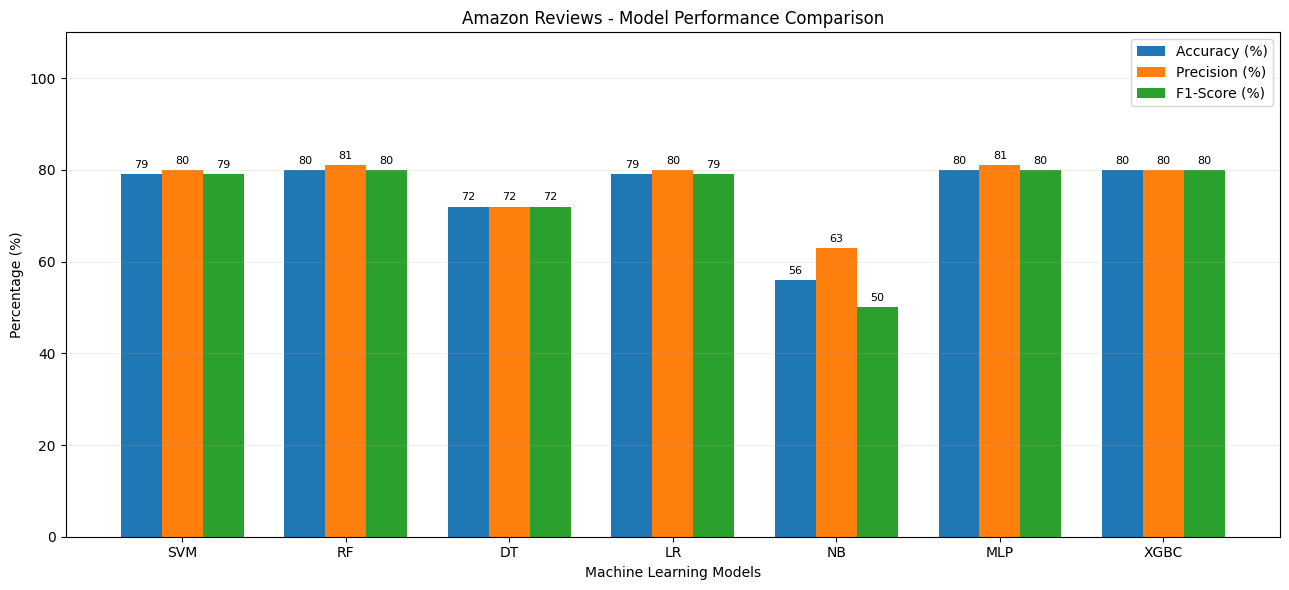

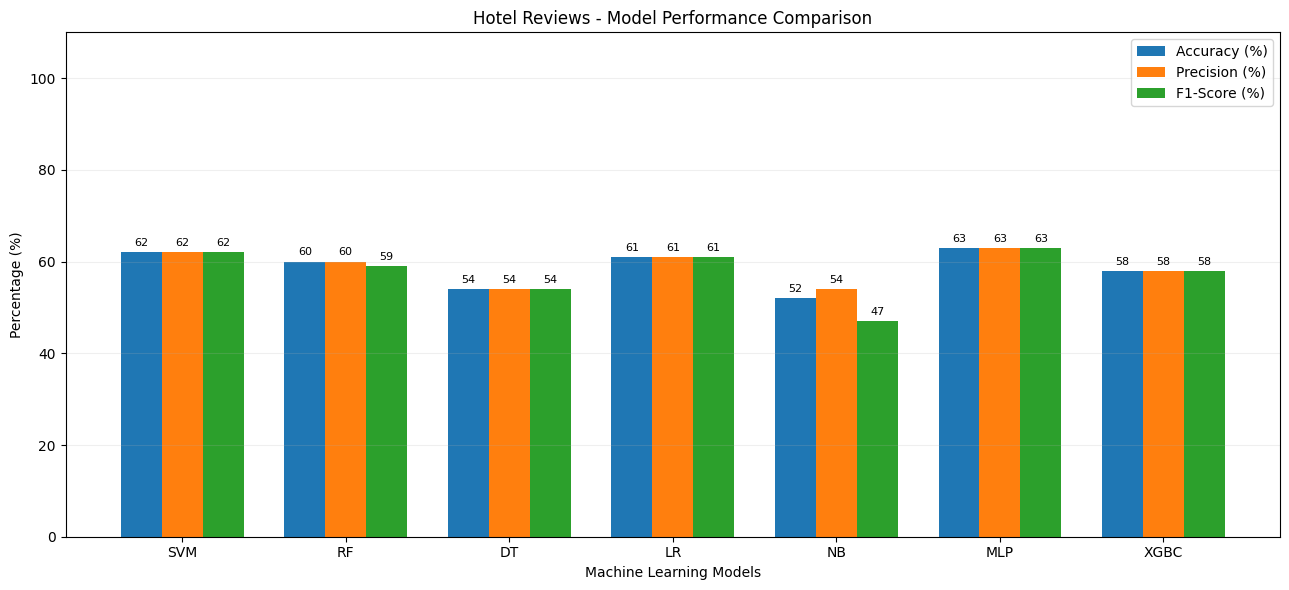

In [ ]:

# Model Performance Visualization - Amazon and Hotel

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

metrics = ["Accuracy (%)", "Precision (%)", "F1-Score (%)"]
models = ["SVM", "RF", "DT", "LR", "NB", "MLP", "XGBC"]

for dataset in ["Amazon Reviews", "Hotel Reviews"]:

    data = results_df[results_df["Dataset"] == dataset].copy()
    data = data.set_index("Model").loc[models]

    for col in metrics:
        data[col] = pd.to_numeric(data[col].astype(str).str.replace("%", ""), errors="raise")

    x = np.arange(7)
    width = 0.25

    plt.figure(figsize=(13, 6))

    for i, metric in enumerate(metrics):
        bars = plt.bar(
            x + (i - 1) * width,
            data[metric],
            width,
            label=metric
        )
        plt.bar_label(bars, fmt="%.0f", padding=3, fontsize=8)

    plt.xticks(x, models)
    plt.ylim(0, 110)
    plt.xlabel("Machine Learning Models")
    plt.ylabel("Percentage (%)")
    plt.title(dataset + " - Model Performance Comparison")
    plt.legend()
    plt.grid(axis="y", alpha=0.2)
    plt.tight_layout()
    plt.show()


FEATURE IMPORTANCE

In [ ]:

import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from IPython.display import display, HTML

rows = []

for name, X, y in [
    ("Amazon reviews", X_amazon, y_amazon),
    ("Hotel reviews", X_hotel, y_hotel)
]:
    labels = pd.factorize(y)[0]

    X_train, X_test, y_train, y_test = train_test_split(
        X, labels, test_size=0.2,
        random_state=42, stratify=labels
    )

    model = RandomForestClassifier(
        n_estimators=100, random_state=42
    )
    model.fit(X_train, y_train)

    importance = pd.Series(
        model.feature_importances_,
        index=X.columns
    ).sort_values(ascending=False).head(4)

    for feature, value in importance.items():
        rows.append([name, feature, f"{value:.4f}"])

df = pd.DataFrame(rows, columns=[
    "Dataset", "Features", "Importance"
])

html = """
<h3 style='text-align:center'>TABLE I<br>FEATURE IMPORTANCE</h3>
<table style='border-collapse:collapse;width:80%;text-align:center'>
<tr>
<th style='border:1px solid black'>Dataset</th>
<th style='border:1px solid black'>Features</th>
<th style='border:1px solid black'>Importance</th>
</tr>
"""

for dataset in df["Dataset"].unique():
    subset = df[df["Dataset"] == dataset]
    for i, (_, row) in enumerate(subset.iterrows()):
        html += "<tr>"
        if i == 0:
            html += f"<td rowspan='4' style='border:1px solid black'>{dataset}</td>"
        html += f"<td style='border:1px solid black'>{row['Features']}</td>"
        html += f"<td style='border:1px solid black'>{row['Importance']}</td>"
        html += "</tr>"

html += "</table>"
display(HTML(html))


With vs Without Metadata


Processing: Amazon Reviews
Removed metadata: ['rating', 'verified_purchase', 'rating_sentiment_mismatch', 'category_Apparel', 'category_Automotive', 'category_Baby', 'category_Beauty', 'category_Books', 'category_Camera', 'category_Electronics', 'category_Furniture', 'category_Grocery', 'category_Health & Personal Care', 'category_Home', 'category_Home Entertainment', 'category_Home Improvement', 'category_Jewelry', 'category_Kitchen', 'category_Lawn and Garden', 'category_Luggage', 'category_Musical Instruments', 'category_Office Products', 'category_Outdoors', 'category_PC', 'category_Pet Products', 'category_Shoes', 'category_Sports', 'category_Tools', 'category_Toys', 'category_Video DVD', 'category_Video Games', 'category_Watches', 'category_Wireless']


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



Processing: Hotel Reviews
Removed metadata: ['review_polarity']

AMAZON REVIEWS - METADATA COMPARISON


,Model,Without Accuracy (%),With Accuracy (%),Improvement (%),Without F1 (%),With F1 (%)
0,SVM,61.17,61.48,0.31,60.99,61.30
1,RF,60.43,80.31,19.88,60.43,80.25
2,DT,54.14,71.60,17.45,54.14,71.60
3,LR,56.93,79.38,22.45,56.51,79.29
4,NB,54.67,56.33,1.67,47.54,49.71
5,MLP,52.93,79.74,26.81,52.52,79.45
6,XGBC,61.50,80.26,18.76,61.49,80.23


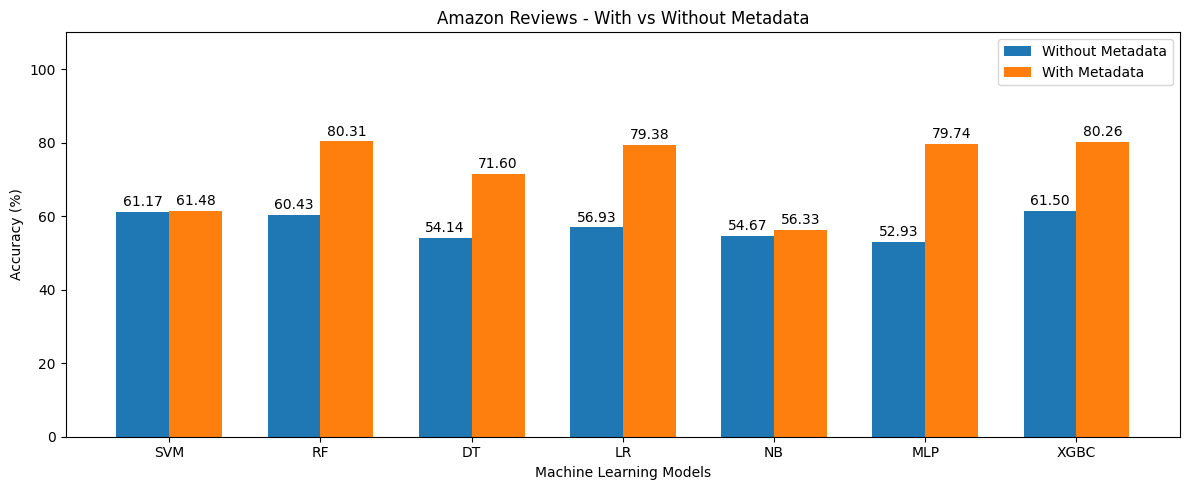


HOTEL REVIEWS - METADATA COMPARISON


,Model,Without Accuracy (%),With Accuracy (%),Improvement (%),Without F1 (%),With F1 (%)
0,SVM,47.81,47.81,0.00,47.25,47.25
1,RF,58.75,59.69,0.94,58.72,59.48
2,DT,54.37,54.37,0.00,54.26,54.33
3,LR,62.81,62.50,-0.31,62.62,62.32
4,NB,52.50,52.50,0.00,47.13,47.13
5,MLP,62.50,61.25,-1.25,62.07,60.03
6,XGBC,59.38,58.13,-1.25,59.27,58.04


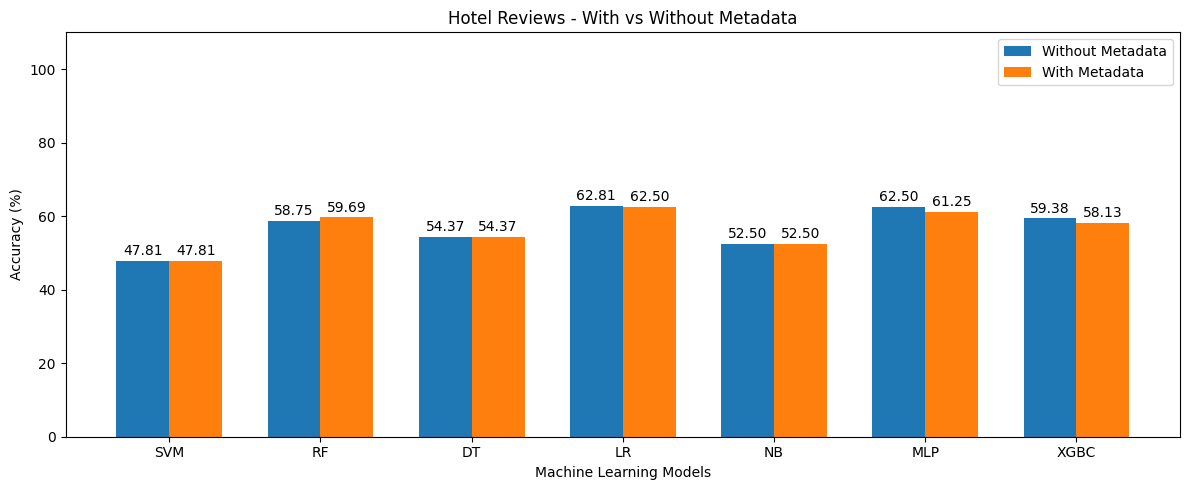

In [ ]:

# WITH vs WITHOUT METADATA - AMAZON AND HOTEL

from sklearn.base import clone

# Define 7 ML models separately
comparison_models = {
    "SVM": SVC(),
    "RF": RandomForestClassifier(random_state=42),
    "DT": DecisionTreeClassifier(random_state=42),
    "LR": LogisticRegression(max_iter=2000),
    "NB": GaussianNB(),
    "MLP": MLPClassifier(max_iter=300, random_state=42),
    "XGBC": XGBClassifier(
        eval_metric="logloss", random_state=42
    )
}

# Metadata columns
metadata = {
    "Amazon Reviews": [
        "rating", "verified_purchase",
        "rating_sentiment_mismatch"
    ],
    "Hotel Reviews": [
        "review_polarity", "hotel_encoded"
    ]
}

comparison_results = []

datasets = [
    ("Amazon Reviews", X_amazon, y_amazon),
    ("Hotel Reviews", X_hotel, y_hotel)
]

for dataset_name, X, y in datasets:

    print("\nProcessing:", dataset_name)

    # Identify metadata columns
    meta_cols = metadata[dataset_name] + [
        col for col in X.columns
        if col.lower().startswith((
            "category_", "product_category_"
        ))
    ]

    # Remove metadata for baseline
    X_without = X.drop(columns=meta_cols, errors="ignore")
    X_with = X.copy()

    removed_cols = [
        col for col in X.columns if col not in X_without.columns
    ]

    print("Removed metadata:", removed_cols)

    if not removed_cols:
        raise ValueError(
            "No metadata columns found for " + dataset_name
        )

    # Numerical labels
    labels = pd.factorize(y)[0]

    # Same train-test split
    train_idx, test_idx = train_test_split(
        np.arange(len(labels)),
        test_size=0.2,
        random_state=42,
        stratify=labels
    )

    for model_name, model in comparison_models.items():

        scores = {}

        for setting, features in [
            ("Without", X_without),
            ("With", X_with)
        ]:

            clf = clone(model)

            clf.fit(
                features.iloc[train_idx],
                labels[train_idx]
            )

            predictions = clf.predict(
                features.iloc[test_idx]
            )

            accuracy = accuracy_score(
                labels[test_idx], predictions
            ) * 100

            f1 = f1_score(
                labels[test_idx],
                predictions,
                average="weighted",
                zero_division=0
            ) * 100

            scores[setting] = (accuracy, f1)

        comparison_results.append({
            "Dataset": dataset_name,
            "Model": model_name,
            "Without Accuracy (%)": round(scores["Without"][0], 2),
            "With Accuracy (%)": round(scores["With"][0], 2),
            "Improvement (%)": round(
                scores["With"][0] - scores["Without"][0], 2
            ),
            "Without F1 (%)": round(scores["Without"][1], 2),
            "With F1 (%)": round(scores["With"][1], 2)
        })

comparison_df = pd.DataFrame(comparison_results)

# DISPLAY AMAZON AND HOTEL RESULTS SEPARATELY

for dataset_name in ["Amazon Reviews", "Hotel Reviews"]:

    data = comparison_df[
        comparison_df["Dataset"] == dataset_name
    ].drop(columns=["Dataset"]).reset_index(drop=True)

    print("\n" + "=" * 65)
    print(dataset_name.upper() + " - METADATA COMPARISON")
    print("=" * 65)

    display(data)

    # Accuracy comparison graph
    x = np.arange(len(data))
    width = 0.35

    plt.figure(figsize=(12, 5))

    bars1 = plt.bar(
        x - width / 2,
        data["Without Accuracy (%)"],
        width,
        label="Without Metadata"
    )

    bars2 = plt.bar(
        x + width / 2,
        data["With Accuracy (%)"],
        width,
        label="With Metadata"
    )

    plt.bar_label(bars1, fmt="%.2f", padding=2)
    plt.bar_label(bars2, fmt="%.2f", padding=2)

    plt.xticks(x, data["Model"])
    plt.xlabel("Machine Learning Models")
    plt.ylabel("Accuracy (%)")
    plt.title(dataset_name + " - With vs Without Metadata")
    plt.ylim(0, 110)
    plt.legend()
    plt.tight_layout()
    plt.show()


Metadata: ['review_polarity']
VADER features: ['positive_score', 'negative_score', 'neutral_score', 'compound_score']


,Model,Approach,Accuracy (%)
0,SVM,Without Metadata,88.12
1,LR,Without Metadata,85.31
2,SVM,With Metadata,88.12
3,LR,With Metadata,85.31
4,SVM,Reduced Overlap,90.31
5,LR,Reduced Overlap,86.88


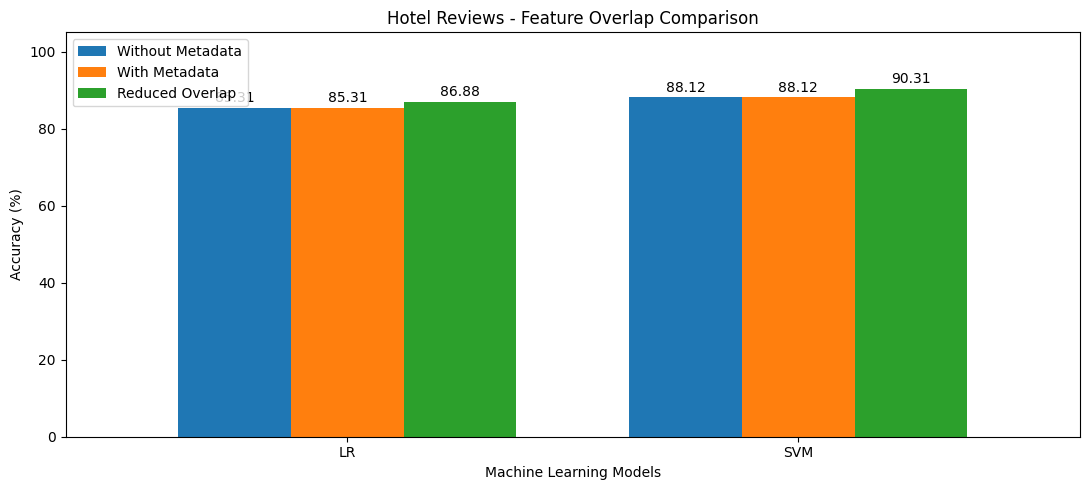

In [ ]:

# HOTEL - REDUCED OVERLAP EXPERIMENT

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from scipy.sparse import hstack, csr_matrix

# Hotel data
texts = hotel_clean["clean_text"].fillna("").astype(str).reset_index(drop=True)
X = X_hotel.reset_index(drop=True)
y = pd.Series(y_hotel).reset_index(drop=True)

# Identify metadata
meta_cols = [
    c for c in ["review_polarity", "hotel_encoded"]
    if c in X.columns
]

# Identify VADER sentiment features
vader_cols = [
    c for c in X.columns
    if c.lower() in [
        "positive_score", "negative_score",
        "neutral_score", "compound_score",
        "pos_score", "neg_score", "neu_score"
    ]
]

print("Metadata:", meta_cols)
print("VADER features:", vader_cols)

# Three feature combinations
feature_sets = {
    "Without Metadata": X.drop(columns=meta_cols),
    "With Metadata": X.copy(),
    "Reduced Overlap": X.drop(columns=vader_cols)
}

# Same train-test split
train_idx, test_idx = train_test_split(
    np.arange(len(y)),
    test_size=0.20,
    random_state=42,
    stratify=y
)

# TF-IDF
tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

T_train = tfidf.fit_transform(texts.iloc[train_idx])
T_test = tfidf.transform(texts.iloc[test_idx])

models = {
    "SVM": LinearSVC(C=1, max_iter=5000, random_state=42),
    "LR": LogisticRegression(C=1, max_iter=3000, random_state=42)
}

results = []

for setting, features in feature_sets.items():

    scaler = StandardScaler()

    F_train = csr_matrix(
        scaler.fit_transform(features.iloc[train_idx])
    )
    F_test = csr_matrix(
        scaler.transform(features.iloc[test_idx])
    )

    X_train = hstack([T_train, F_train]).tocsr()
    X_test = hstack([T_test, F_test]).tocsr()

    for name, model in models.items():

        clf = clone(model)
        clf.fit(X_train, y.iloc[train_idx])
        pred = clf.predict(X_test)

        results.append({
            "Model": name,
            "Approach": setting,
            "Accuracy (%)": round(
                accuracy_score(y.iloc[test_idx], pred) * 100, 2
            )
        })

hotel_overlap_results = pd.DataFrame(results)

display(hotel_overlap_results)

# Comparison graph
graph_data = hotel_overlap_results.pivot(
    index="Model",
    columns="Approach",
    values="Accuracy (%)"
)

graph_data = graph_data[
    ["Without Metadata", "With Metadata", "Reduced Overlap"]
]

ax = graph_data.plot(
    kind="bar",
    figsize=(11, 5),
    width=0.75
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=2)

plt.title("Hotel Reviews - Feature Overlap Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=0)
plt.ylim(0, 105)
plt.legend()
plt.tight_layout()
plt.show()


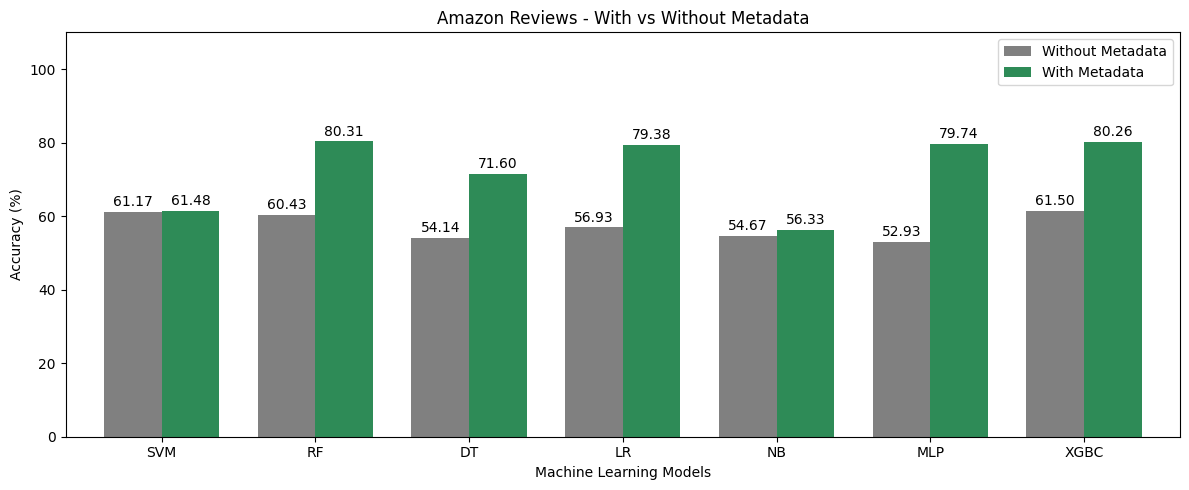

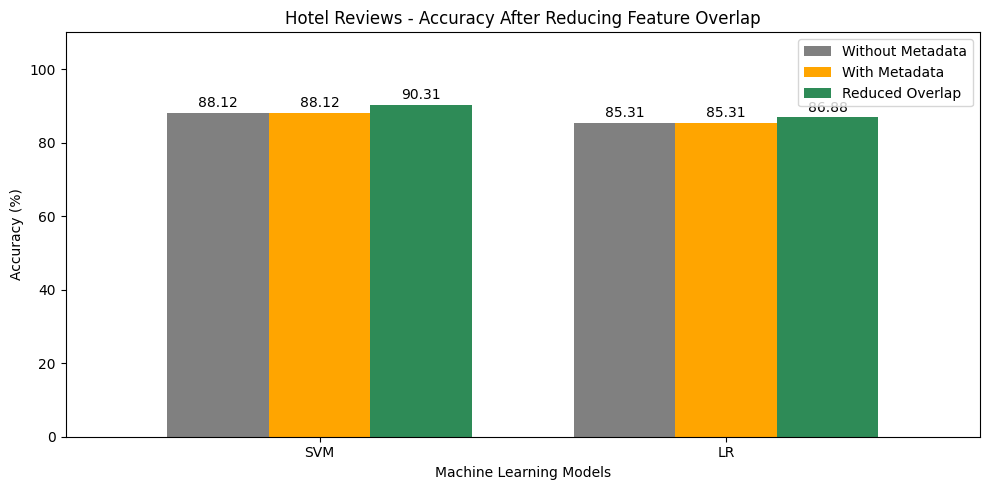


HOTEL ACCURACY IMPROVEMENT


Approach,Without Metadata,With Metadata,Reduced Overlap,Improvement (pp)
Model,,,,
SVM,88.12,88.12,90.31,2.19
LR,85.31,85.31,86.88,1.57


In [ ]:

# FINAL ACCURACY COMPARISON - AMAZON AND HOTEL

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# AMAZON - ORIGINAL METADATA COMPARISON

amazon_results = comparison_df[
    comparison_df["Dataset"] == "Amazon Reviews"
].copy()

amazon_results = amazon_results.set_index("Model")

amazon_graph = amazon_results[
    ["Without Accuracy (%)", "With Accuracy (%)"]
].rename(columns={
    "Without Accuracy (%)": "Without Metadata",
    "With Accuracy (%)": "With Metadata"
})

ax = amazon_graph.plot(
    kind="bar",
    figsize=(12, 5),
    width=0.75,
    color=["gray", "seagreen"]
)

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", padding=2)

plt.title("Amazon Reviews - With vs Without Metadata")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=0)
plt.ylim(0, 110)
plt.legend()
plt.tight_layout()
plt.show()


# HOTEL - FEATURE OVERLAP COMPARISON

hotel_graph = hotel_overlap_results.pivot(
    index="Model",
    columns="Approach",
    values="Accuracy (%)"
)

hotel_graph = hotel_graph.reindex(
    index=["SVM", "LR"],
    columns=[
        "Without Metadata",
        "With Metadata",
        "Reduced Overlap"
    ]
)

ax = hotel_graph.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.75,
    color=["gray", "orange", "seagreen"]
)

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", padding=2)

plt.title("Hotel Reviews - Accuracy After Reducing Feature Overlap")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=0)
plt.ylim(0, 110)
plt.legend()
plt.tight_layout()
plt.show()


# HOTEL - ACCURACY IMPROVEMENT TABLE

hotel_summary = hotel_graph.copy()

hotel_summary["Improvement (pp)"] = (
    hotel_summary["Reduced Overlap"] -
    hotel_summary["With Metadata"]
).round(2)

print("\nHOTEL ACCURACY IMPROVEMENT")
display(hotel_summary.round(2))
